In [1]:
# Core libraries
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Machine-learning tools
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

In [2]:
# Trim mixture first-level events and retain their
# corresponding secondary events.

#DATA_DIR = Path(".")
DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

MIXTURE_EVENT_DIR = (
    DATA_DIR / "events_g_CD_mix"
)

MIXTURE_SUB_EVENT_DIR = (
    DATA_DIR / "sub_events_g_CD_mix"
)

MIXTURE_TRIM_EVENT_DIR = (
    DATA_DIR / "trim_events_g_CD_mix"
)

MIXTURE_TRIM_SUB_EVENT_DIR = (
    DATA_DIR / "trim_sub_events_g_CD_mix"
)

MIXTURE_TRIM_EVENT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MIXTURE_TRIM_SUB_EVENT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Remove previously generated files so that stale files
# are not retained between runs.
for output_file in (
    MIXTURE_TRIM_EVENT_DIR.glob("*.csv")
):
    output_file.unlink()

for output_file in (
    MIXTURE_TRIM_SUB_EVENT_DIR.glob("*.csv")
):
    output_file.unlink()

retained_event_count = 0
retained_sub_event_count = 0
skipped_recordings = []

for event_file in sorted(
    MIXTURE_EVENT_DIR.glob("*.csv")
):
    events = pd.read_csv(
        event_file
    )

    density = (
        events["num_sub_events"]
        / events["dwell_time_us"]
    )

    log_density = np.log(
        density
    )

    median_log_density = np.median(
        log_density
    )

    mad = np.median(
        np.abs(
            log_density
            - median_log_density
        )
    )

    # A robust Z score cannot be calculated when MAD
    # is zero or nonfinite.
    if mad == 0 or not np.isfinite(mad):
        skipped_recordings.append(
            event_file.name
        )

        print(
            f"Skipped {event_file.name}: "
            "MAD could not be calculated because the "
            "recording contained insufficient event "
            "variation."
        )

        continue

    robust_z = (
        0.6745
        * (
            log_density
            - median_log_density
        )
        / mad
    )

    trimmed_events = events.loc[
        np.abs(robust_z) <= 3
    ].copy()

    if trimmed_events.empty:
        print(
            f"Skipped {event_file.name}: "
            "no first-level events remained after "
            "trimming."
        )

        continue

    trimmed_events.to_csv(
        MIXTURE_TRIM_EVENT_DIR
        / event_file.name,
        index=False,
    )

    retained_event_count += len(
        trimmed_events
    )

    # Match the secondary-event file to the current
    # first-level-event file.
    sub_event_file = (
        MIXTURE_SUB_EVENT_DIR
        / f"{event_file.stem}_sub.csv"
    )

    if not sub_event_file.exists():
        print(
            f"Warning: no matching secondary-event "
            f"file for {event_file.name}"
        )

        continue

    sub_events = pd.read_csv(
        sub_event_file
    )

    keep_sub_event = np.zeros(
        len(sub_events),
        dtype=bool,
    )

    for _, event in trimmed_events.iterrows():
        keep_sub_event |= (
            (
                sub_events["sub_start_time_s"]
                >= event["start_time_s"]
            )
            & (
                sub_events["sub_end_time_s"]
                <= event["end_time_s"]
            )
        )

    trimmed_sub_events = sub_events.loc[
        keep_sub_event
    ].copy()

    if trimmed_sub_events.empty:
        print(
            f"Warning: no secondary events remained "
            f"for {event_file.name}"
        )

        continue

    trimmed_sub_events.to_csv(
        MIXTURE_TRIM_SUB_EVENT_DIR
        / sub_event_file.name,
        index=False,
    )

    retained_sub_event_count += len(
        trimmed_sub_events
    )

print()

print(
    f"Retained {retained_event_count:,} "
    "mixture first-level events."
)

print(
    f"Retained {retained_sub_event_count:,} "
    "mixture secondary events."
)

print(
    f"Skipped {len(skipped_recordings)} "
    "recordings because MAD could not be calculated."
)


Retained 8,335 mixture first-level events.
Retained 94,867 mixture secondary events.
Skipped 0 recordings because MAD could not be calculated.


In [3]:
# Assemble the two-AA mixture dataset from trimmed events,
# secondary events, and open-pore baseline measurements.

MIXTURE_BASELINE_DIR = (
    DATA_DIR / "final_baseline_info_g_CD_mix"
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Each digit identifies the cluster-specific classifier
# applied at the second level.
CLUSTER_PAIR_MAP = {
    "FP": 13,
    "GQ": 30,
    "LW": 20,
    "MV": 23,
    "DY": 40,
    "RV": 34,
    "HN": 10,
    "SL": 12,
    "HM": 12,
    "DP": 14,
    "SA": 10,
    "LE": 20,
    "DT": 40,
    "TV": 30,
    "MD": 24,
    "LI": 23,
    "LD": 24,
    "GH": 13,
    "VD": 34,
    "SD": 14,
}

assembled_datasets = []

for sub_event_file in sorted(
    MIXTURE_TRIM_SUB_EVENT_DIR.glob("*.csv")
):
    recording_id = (
        sub_event_file.stem.removesuffix("_sub")
    )

    mixture_label = (
        recording_id.split("_")[0]
    )

    if mixture_label not in CLUSTER_PAIR_MAP:
        raise ValueError(
            f"No cluster-pair mapping was found for "
            f"{mixture_label}."
        )

    event_file = (
        MIXTURE_TRIM_EVENT_DIR
        / f"{recording_id}.csv"
    )

    baseline_file = (
        MIXTURE_BASELINE_DIR
        / f"{recording_id}_final.csv"
    )

    if not event_file.exists():
        raise FileNotFoundError(
            f"Missing trimmed event file: "
            f"{event_file.name}"
        )

    if not baseline_file.exists():
        raise FileNotFoundError(
            f"Missing baseline file: "
            f"{baseline_file.name}"
        )

    sub_events = pd.read_csv(
        sub_event_file
    )

    first_level_events = pd.read_csv(
        event_file
    )

    baseline_data = pd.read_csv(
        baseline_file
    )

    if baseline_data.empty:
        raise ValueError(
            f"Baseline file is empty: "
            f"{baseline_file.name}"
        )

    open_pore_rms = (
        baseline_data["rms"].iloc[0]
    )

    matched_rows = []

    for _, sub_event in sub_events.iterrows():
        parent_event = first_level_events.loc[
            (
                first_level_events["start_time_s"]
                <= sub_event["sub_start_time_s"]
            )
            & (
                first_level_events["end_time_s"]
                >= sub_event["sub_end_time_s"]
            )
        ]

        if parent_event.empty:
            continue

        parent_event = parent_event.iloc[0]

        event_id = (
            f"{recording_id}_"
            f"{int(parent_event['event_index'])}"
        )

        matched_rows.append({
            "sub_pre_interaction_current":
                sub_event[
                    "sub_pre_interaction_current"
                ],

            "sub_post_interaction_current":
                sub_event[
                    "sub_post_interaction_current"
                ],

            # I1
            "first_level_current":
                sub_event["sub_mode_baseline"],

            # σ1
            "first_level_stdev":
                parent_event["blockage_stdev"],

            # σ0
            "open_pore_rms":
                open_pore_rms,

            "dwell_time_us":
                parent_event["dwell_time_us"],

            # Parent first-level blockage
            "event_id":
                event_id,

            # Single-pore recording
            "dataset_id":
                recording_id,

            # Two-AA mixture identity
            "mixture_label":
                mixture_label,

            # Pair of cluster-specific classifiers
            "cluster_pair":
                CLUSTER_PAIR_MAP[
                    mixture_label
                ],
        })

    if matched_rows:
        assembled_datasets.append(
            pd.DataFrame(matched_rows)
        )

if not assembled_datasets:
    raise ValueError(
        "No matched mixture secondary events were found."
    )

df = pd.concat(
    assembled_datasets,
    ignore_index=True,
)

required_columns = [
    "sub_pre_interaction_current",
    "sub_post_interaction_current",
    "first_level_current",
    "first_level_stdev",
    "open_pore_rms",
    "dwell_time_us",
    "event_id",
    "dataset_id",
    "mixture_label",
    "cluster_pair",
]

if df[required_columns].isna().any().any():
    missing_columns = (
        df[required_columns]
        .columns[
            df[required_columns]
            .isna()
            .any()
        ]
        .tolist()
    )

    raise ValueError(
        f"Missing values detected in: "
        f"{missing_columns}"
    )

if (df["open_pore_rms"] <= 0).any():
    raise ValueError(
        "All open-pore RMS values must be positive."
    )

print(
    f"Mixture identities: "
    f"{df['mixture_label'].nunique()}"
)

print(
    f"Cluster pairs: "
    f"{df['cluster_pair'].nunique()}"
)

print(
    f"Secondary events: "
    f"{len(df):,}"
)

print(
    f"First-level events: "
    f"{df['event_id'].nunique():,}"
)

print(
    f"Single-pore recordings: "
    f"{df['dataset_id'].nunique():,}"
)

display(df.head())

Mixture identities: 20
Cluster pairs: 10
Secondary events: 94,867
First-level events: 7,052
Single-pore recordings: 106


,sub_pre_interaction_current,sub_post_interaction_current,first_level_current,first_level_stdev,open_pore_rms,dwell_time_us,event_id,dataset_id,mixture_label,cluster_pair
0,101.623535,120.849610,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
1,46.081543,117.255320,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
2,107.879640,115.173340,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
3,106.658936,115.478516,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
4,107.116700,117.340090,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14


In [4]:
# Encode cluster-pair labels, split by parent
# first-level blockage, and construct classifier features.

FEATURE_NAMES = [
    "Baseline Ratio",
    "Z Score",
    "Per-event Impact",
    "Per-time Impact",
]

# Encode the cluster-pair labels.
cluster_label_encoder = LabelEncoder()

cluster_label_encoder.fit(
    df["cluster_pair"]
)

encoded_cluster_labels = (
    cluster_label_encoder.transform(
        df["cluster_pair"]
    )
)

cluster_label_mapping = {
    int(cluster_pair): int(encoded_label)
    for cluster_pair, encoded_label
    in zip(
        cluster_label_encoder.classes_,
        cluster_label_encoder.transform(
            cluster_label_encoder.classes_
        ),
    )
}

print(
    "Cluster-pair label mapping:",
    cluster_label_mapping,
)

# Each event_id represents one parent first-level blockage.
event_table = (
    df[
        [
            "event_id",
            "dataset_id",
            "mixture_label",
            "cluster_pair",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "cluster_pair",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)

# Confirm that each first-level event belongs to only
# one recording, mixture, and cluster pair.
event_validation = (
    df.groupby("event_id")
    .agg(
        dataset_count=(
            "dataset_id",
            "nunique",
        ),
        mixture_count=(
            "mixture_label",
            "nunique",
        ),
        cluster_pair_count=(
            "cluster_pair",
            "nunique",
        ),
    )
)

if (
    (
        event_validation["dataset_count"]
        != 1
    ).any()
    or (
        event_validation["mixture_count"]
        != 1
    ).any()
    or (
        event_validation["cluster_pair_count"]
        != 1
    ).any()
):
    raise ValueError(
        "Each event_id must correspond to one recording, "
        "one mixture, and one cluster pair."
    )

# Deterministic 60:20:20 target split within each
# cluster-pair class.
rng = np.random.default_rng(42)
split_assignment = {}

for cluster_pair in sorted(
    event_table["cluster_pair"].unique()
):
    cluster_event_ids = (
        event_table.loc[
            event_table["cluster_pair"]
            == cluster_pair,
            "event_id",
        ]
        .sort_values()
        .to_numpy()
    )

    cluster_event_ids = rng.permutation(
        cluster_event_ids
    )

    number_of_events = len(
        cluster_event_ids
    )

    number_train = max(
        1,
        int(
            np.floor(
                0.60 * number_of_events
            )
        ),
    )

    number_validation = max(
        1,
        int(
            np.floor(
                0.20 * number_of_events
            )
        ),
    )

    # Leave at least one event for testing.
    if (
        number_train
        + number_validation
        >= number_of_events
    ):
        number_validation = max(
            0,
            number_of_events
            - number_train
            - 1,
        )

    train_event_ids = (
        cluster_event_ids[:number_train]
    )

    validation_event_ids = (
        cluster_event_ids[
            number_train:
            number_train
            + number_validation
        ]
    )

    test_event_ids = (
        cluster_event_ids[
            number_train
            + number_validation:
        ]
    )

    for event_id in train_event_ids:
        split_assignment[event_id] = "train"

    for event_id in validation_event_ids:
        split_assignment[event_id] = "validation"

    for event_id in test_event_ids:
        split_assignment[event_id] = "test"

# Every single-pore recording must contribute at least
# one first-level event to the training set because
# recording-level aggregate features are calculated
# from training events only.
for dataset_id in sorted(
    event_table["dataset_id"].unique()
):
    recording_event_ids = (
        event_table.loc[
            event_table["dataset_id"]
            == dataset_id,
            "event_id",
        ]
        .sort_values()
        .tolist()
    )

    has_training_event = any(
        split_assignment[event_id] == "train"
        for event_id in recording_event_ids
    )

    if not has_training_event:
        event_to_move = (
            recording_event_ids[0]
        )

        split_assignment[
            event_to_move
        ] = "train"

df["split"] = df["event_id"].map(
    split_assignment
)

if df["split"].isna().any():
    raise ValueError(
        "Some mixture observations were not assigned "
        "to a split."
    )

train_mask = df["split"] == "train"
validation_mask = (
    df["split"] == "validation"
)
test_mask = df["split"] == "test"

# Calculate recording-level aggregate values using
# training observations only.
training_rows = df.loc[
    train_mask
].copy()

training_event_count = (
    training_rows
    .groupby("dataset_id")
    .size()
    .rename(
        "training_secondary_event_count"
    )
)

training_dwell_time = (
    training_rows[
        [
            "dataset_id",
            "event_id",
            "dwell_time_us",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .groupby("dataset_id")[
        "dwell_time_us"
    ]
    .sum()
    .rename(
        "training_first_level_dwell_time"
    )
)

training_aggregates = pd.concat(
    [
        training_event_count,
        training_dwell_time,
    ],
    axis=1,
)

training_aggregates[
    "training_event_frequency"
] = (
    training_aggregates[
        "training_secondary_event_count"
    ]
    / training_aggregates[
        "training_first_level_dwell_time"
    ]
)

if (
    training_aggregates.isna().any().any()
    or (
        training_aggregates[
            "training_secondary_event_count"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_first_level_dwell_time"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_event_frequency"
        ]
        <= 0
    ).any()
):
    raise ValueError(
        "Invalid training-derived aggregate values "
        "detected."
    )

# Apply the training-derived aggregate values unchanged
# to all three splits.
feature_source = df.copy()

feature_source[
    "training_secondary_event_count"
] = feature_source["dataset_id"].map(
    training_aggregates[
        "training_secondary_event_count"
    ]
)

feature_source[
    "training_first_level_dwell_time"
] = feature_source["dataset_id"].map(
    training_aggregates[
        "training_first_level_dwell_time"
    ]
)

feature_source[
    "training_event_frequency"
] = feature_source["dataset_id"].map(
    training_aggregates[
        "training_event_frequency"
    ]
)

aggregate_columns = [
    "training_secondary_event_count",
    "training_first_level_dwell_time",
    "training_event_frequency",
]

if (
    feature_source[
        aggregate_columns
    ]
    .isna()
    .any()
    .any()
):
    missing_recordings = (
        feature_source.loc[
            feature_source[
                aggregate_columns
            ]
            .isna()
            .any(axis=1),
            "dataset_id",
        ]
        .unique()
        .tolist()
    )

    raise ValueError(
        "No training-derived aggregate values for: "
        f"{missing_recordings}"
    )

# Construct the four classifier features.
feature_source["Baseline Ratio"] = (
    feature_source[
        "sub_post_interaction_current"
    ]
    / feature_source[
        "first_level_current"
    ]
)

feature_source["Z Score"] = (
    (
        feature_source[
            "sub_post_interaction_current"
        ]
        - feature_source[
            "first_level_current"
        ]
    )
    / feature_source[
        "open_pore_rms"
    ]
)

feature_source["Per-event Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_secondary_event_count"
    ]
)

feature_source["Per-time Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_event_frequency"
    ]
)

feature_values = (
    feature_source[
        FEATURE_NAMES
    ]
    .to_numpy()
)

if not np.isfinite(feature_values).all():
    raise ValueError(
        "Nonfinite values detected in "
        "classifier features."
    )

# Create the final feature matrices.
X_train = (
    feature_source.loc[
        train_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

X_val = (
    feature_source.loc[
        validation_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

X_test = (
    feature_source.loc[
        test_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    cluster_label_encoder.transform(
        feature_source.loc[
            train_mask,
            "cluster_pair",
        ]
    )
)

y_val = (
    cluster_label_encoder.transform(
        feature_source.loc[
            validation_mask,
            "cluster_pair",
        ]
    )
)

y_test = (
    cluster_label_encoder.transform(
        feature_source.loc[
            test_mask,
            "cluster_pair",
        ]
    )
)

# Mixture identities corresponding to the test rows.
true_mixture_labels = (
    feature_source.loc[
        test_mask,
        "mixture_label",
    ]
    .astype(str)
    .reset_index(drop=True)
    .to_numpy()
)

# Retain first-level-event groups if grouped evaluation
# is added later.
groups_train = (
    feature_source.loc[
        train_mask,
        "event_id",
    ]
    .reset_index(drop=True)
    .to_numpy()
)

# Save the event-level split assignment.
split_assignment_df = (
    feature_source[
        [
            "event_id",
            "dataset_id",
            "mixture_label",
            "cluster_pair",
            "split",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "cluster_pair",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)

split_assignment_df.to_csv(
    OUTPUT_DIR
    / "two_level_split_assignment.csv",
    index=False,
)

print(
    f"Training observations: "
    f"{len(X_train):,}"
)

print(
    f"Validation observations: "
    f"{len(X_val):,}"
)

print(
    f"Test observations: "
    f"{len(X_test):,}"
)

print(
    "\nParent first-level events by split:"
)

print(
    split_assignment_df["split"]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ],
        fill_value=0,
    )
)

Cluster-pair label mapping: {10: 0, 12: 1, 13: 2, 14: 3, 20: 4, 23: 5, 24: 6, 30: 7, 34: 8, 40: 9}
Training observations: 57,337
Validation observations: 17,906
Test observations: 19,624

Parent first-level events by split:
split
train         4228
validation    1406
test          1418
Name: count, dtype: int64


In [5]:
# Train the first-level cluster-pair classifier.

cluster_pair_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1,
)

cluster_pair_classifier.fit(
    X_train,
    y_train,
)

CLUSTER_PAIR_MODEL_PATH = (
    OUTPUT_DIR
    / "two_level_cluster_pair_classifier.joblib"
)

joblib.dump(
    cluster_pair_classifier,
    CLUSTER_PAIR_MODEL_PATH,
)

training_accuracy = (
    cluster_pair_classifier.score(
        X_train,
        y_train,
    )
)

validation_accuracy = (
    cluster_pair_classifier.score(
        X_val,
        y_val,
    )
)

test_accuracy = (
    cluster_pair_classifier.score(
        X_test,
        y_test,
    )
)

cluster_pair_metrics = pd.DataFrame({
       "metric": [
        "training_accuracy",
        "validation_accuracy",
        "test_accuracy",
    ],
    "value": [
        training_accuracy,
        validation_accuracy,
        test_accuracy,
    ],
})

cluster_pair_metrics.to_csv(
    OUTPUT_DIR
    / "two_level_cluster_pair_metrics.csv",
    index=False,
)

display(cluster_pair_metrics)

print(
    f"Model saved to: "
    f"{CLUSTER_PAIR_MODEL_PATH.resolve()}"
)

,metric,value
0,training_accuracy,0.999878
1,validation_accuracy,0.974031
2,test_accuracy,0.945016


Model saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/two_level_cluster_pair_classifier.joblib


In [6]:
# Apply the five cluster-specific single-AA classifiers
# using batch prediction.

CLUSTER_IDS = [
    0,
    1,
    2,
    3,
    4,
]


def load_cluster_model(cluster_id):
    model_path = (
        OUTPUT_DIR
        / f"cluster{cluster_id}_single_AA_classifier.joblib"
    )

    label_mapping_path = (
        OUTPUT_DIR
        / f"cluster{cluster_id}_label_mapping.joblib"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Missing cluster-specific model: "
            f"{model_path}"
        )

    if not label_mapping_path.exists():
        raise FileNotFoundError(
            f"Missing cluster-specific label mapping: "
            f"{label_mapping_path}"
        )

    model = joblib.load(
        model_path
    )

    label_mapping = joblib.load(
        label_mapping_path
    )

    inverse_label_mapping = {
        int(encoded_label): aa_label
        for aa_label, encoded_label
        in label_mapping.items()
    }

    return (
        model,
        inverse_label_mapping,
    )


# Load each cluster-specific classifier once.
cluster_models = {
    cluster_id: load_cluster_model(
        cluster_id
    )
    for cluster_id in CLUSTER_IDS
}


# Use a single CPU thread during prediction to avoid
# repeated parallel-worker overhead in Jupyter.
cluster_pair_classifier.set_params(
    n_jobs=1
)

for cluster_id in CLUSTER_IDS:
    cluster_models[
        cluster_id
    ][0].set_params(
        n_jobs=1
    )

    
# First-level cluster-pair prediction.
predicted_cluster_pair_encoded = (
    cluster_pair_classifier.predict(
        X_test
    )
)

predicted_cluster_pairs = (
    cluster_label_encoder.inverse_transform(
        predicted_cluster_pair_encoded
    )
)

predicted_cluster_strings = np.asarray([
    str(int(cluster_pair)).zfill(2)
    for cluster_pair in predicted_cluster_pairs
])


if not all(
    len(cluster_pair) == 2
    for cluster_pair in predicted_cluster_strings
):
    raise ValueError(
        "Every predicted cluster pair must contain "
        "exactly two cluster IDs."
    )


# Store the two predicted AA components for each row.
predicted_components = np.empty(
    (
        len(X_test),
        2,
    ),
    dtype=object,
)


# Predict all observations assigned to the same
# cluster in one batch.
for component_position in range(2):
    cluster_ids_at_position = np.asarray([
        int(cluster_pair[component_position])
        for cluster_pair in predicted_cluster_strings
    ])

    for cluster_id in CLUSTER_IDS:
        row_mask = (
            cluster_ids_at_position
            == cluster_id
        )

        if not row_mask.any():
            continue

        (
            single_aa_classifier,
            inverse_label_mapping,
        ) = cluster_models[
            cluster_id
        ]

        batch_features = (
            X_test.loc[
                row_mask,
                FEATURE_NAMES,
            ]
        )

        encoded_predictions = (
            single_aa_classifier.predict(
                batch_features
            )
        )

        predicted_components[
            row_mask,
            component_position,
        ] = [
            inverse_label_mapping[
                int(encoded_label)
            ]
            for encoded_label
            in encoded_predictions
        ]


predicted_mixture_labels = np.asarray([
    "".join(components)
    for components in predicted_components
])

true_mixture_labels = np.asarray(
    true_mixture_labels,
    dtype=str,
)


if (
    len(predicted_mixture_labels)
    != len(true_mixture_labels)
):
    raise ValueError(
        "The numbers of predicted and true mixture "
        "labels do not match."
    )


cluster_pair_accuracy = accuracy_score(
    y_test,
    predicted_cluster_pair_encoded,
)

mixture_component_accuracy = accuracy_score(
    true_mixture_labels,
    predicted_mixture_labels,
)


two_level_metrics = pd.DataFrame({
    "metric": [
        "cluster_pair_accuracy",
        "mixture_component_accuracy",
    ],
    "value": [
        cluster_pair_accuracy,
        mixture_component_accuracy,
    ],
})


two_level_predictions = pd.DataFrame({
    "true_mixture": true_mixture_labels,
    "true_cluster_pair": (
        cluster_label_encoder.inverse_transform(
            y_test
        )
    ),
    "predicted_cluster_pair": (
        predicted_cluster_pairs
    ),
    "predicted_mixture": (
        predicted_mixture_labels
    ),
})


two_level_metrics.to_csv(
    OUTPUT_DIR
    / "two_level_final_metrics.csv",
    index=False,
)

two_level_predictions.to_csv(
    OUTPUT_DIR
    / "two_level_predictions.csv",
    index=False,
)


display(two_level_metrics)
display(two_level_predictions.head())

,metric,value
0,cluster_pair_accuracy,0.945016
1,mixture_component_accuracy,0.076998


,true_mixture,true_cluster_pair,predicted_cluster_pair,predicted_mixture
0,DP,14,14,PK
1,DP,14,14,SK
2,DP,14,14,HK
3,DP,14,14,SK
4,DP,14,14,PK


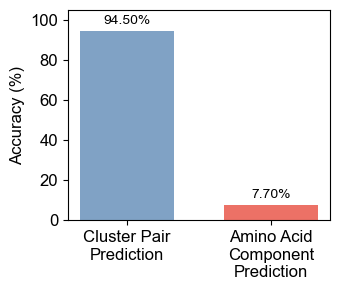

Accuracy plot saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/two_level_accuracy_drop.png


In [7]:
# Plot the accuracy decrease across the two-level workflow.

accuracy_values = [
    cluster_pair_accuracy * 100,
    mixture_component_accuracy * 100,
]

accuracy_labels = [
    "Cluster Pair\nPrediction",
    "Amino Acid\nComponent\nPrediction",
]

bar_colors = [
    "#80A2C5",
    "#EC7166",
]


plt.rcParams["font.family"] = "Arial"

fig, ax = plt.subplots(
    figsize=(3.5, 3)
)

bars = ax.bar(
    accuracy_labels,
    accuracy_values,
    color=bar_colors,
    width=0.65,
)

ax.set_ylim(
    0,
    105,
)

ax.set_ylabel(
    "Accuracy (%)",
    fontsize=12,
)

ax.tick_params(
    axis="both",
    labelsize=12,
)

for bar, accuracy_value in zip(
    bars,
    accuracy_values,
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        accuracy_value + 2,
        f"{accuracy_value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
    )

fig.tight_layout()

ACCURACY_PLOT_PATH = (
    OUTPUT_DIR
    / "two_level_accuracy_drop.png"
)

fig.savefig(
    ACCURACY_PLOT_PATH,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    f"Accuracy plot saved to: "
    f"{ACCURACY_PLOT_PATH.resolve()}"
)